# Which flower toy should the store sell? Analysis on the Project 2 warehouse

This notebook reads the **dbt marts in BigQuery through SQLAlchemy** and answers the business question with pandas:

1. Pipeline integrity: do the warehouse row counts equal the raw source?
2. Which kind of flower toy has demand, growth and satisfaction?
3. **Monthly trend** of that demand
4. **Top-selling products** (review volume is the demand proxy, the dataset has no sales)
5. **Customer segmentation** by purchase (review) behaviour
6. Why people buy it, and what to improve
7. Is "DIY" itself the trend?
8. Amazon 2026: does the 2023 answer still hold?

Data: Amazon Reviews 2023, Toys & Games (US). Reviews end on 2023-09-11, so every year-on-year comparison uses January–September, and growth is read **relative to the whole toy market** because the dataset itself thins out in 2023.

In [1]:
import os
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

PROJECT = os.environ.get('PROJECT2_GCP_PROJECT', 'united-firefly-509307-h9')
engine = create_engine(f'bigquery://{PROJECT}', location='US')   # SQLAlchemy engine on the warehouse

def q(sql):
    """Run a query on the warehouse and return a DataFrame. Only small mart tables are read."""
    with engine.connect() as con:
        return pd.read_sql_query(text(sql), con)

BRICK = 'Brick flower bouquets & bonsai (adult display)'   # the play pattern this analysis ends on
BLUE, GREY, INK = '#2a78d6', '#a3a29c', '#1f2937'
plt.rcParams.update({'font.family': 'Arial', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c3c2b7', 'figure.dpi': 110})

## 1. Pipeline integrity
The star schema must hold every raw record. The same check runs as a dbt test on every build.

In [2]:
integrity = q('''
select 'products' as entity,
       (select count(*) from project2_raw.main_amazon_products_raw) as raw_rows,
       (select count(*) from project2_analytics.dim_product) as warehouse_rows
union all
select 'reviews',
       (select count(*) from project2_raw.main_amazon_reviews_raw),
       (select count(*) from project2_analytics.fact_reviews)
''')
integrity['match'] = integrity.raw_rows == integrity.warehouse_rows
integrity

,entity,raw_rows,warehouse_rows,match
0,reviews,16260406,16260406,True
1,products,890874,890874,True


In [3]:
q('''
select (select count(*) from project2_analytics.dim_customer) as customers,
       (select count(*) from project2_analytics.dim_date) as review_dates,
       (select count(*) from project2_analytics.dim_flower_product) as flower_products,
       (select count(*) from project2_analytics.fact_flower_reviews) as flower_reviews,
       (select count(*) from project2_analytics.dim_play_pattern) as play_patterns
''')

,customers,review_dates,flower_products,flower_reviews,play_patterns
0,8116226,8352,3650,44019,22


## 2. Which kind of flower toy?
`mart_flower_pattern_trend` has one row per **play pattern** (how the toy is used). Interest = reviews written Jan–Sep 2023; satisfaction = average rating; `relative_growth_index` = the pattern's 2023/2022 growth divided by the toy market's (1.0 = same as the market).

In [4]:
trend = q('''
select p.play_pattern, p.play_pattern as pattern, d.is_diy, p.products, p.brands, p.reviews,
       p.reviews_2022_jan_sep as rv_2022, p.reviews_2023_jan_sep as rv_2023,
       p.relative_growth_index as growth_vs_market, p.avg_rating, p.low_rating_pct, p.new_products_2022_23, p.quadrant
from project2_marts.mart_flower_pattern_trend p
join project2_analytics.dim_play_pattern d using (play_pattern)
order by p.reviews_2023_jan_sep desc
''')
trend.drop(columns=['play_pattern']).head(12)

,pattern,is_diy,products,brands,reviews,rv_2022,rv_2023,growth_vs_market,avg_rating,low_rating_pct,new_products_2022_23,quadrant
0,Brick flower bouquets & bonsai (adult display),True,350,226,4793,1135,2002,2.76,4.29,10.87,296,"A high interest, high satisfaction"
1,Flower-image puzzles & cards,False,1546,754,12846,1803,892,0.77,4.05,18.92,352,"B high interest, low satisfaction (improve)"
2,Toddler flower-garden stacking sets,True,237,186,8177,1235,795,1.01,4.67,4.27,97,"A high interest, high satisfaction"
3,Solar dancing flowers & electronic,False,230,147,2809,261,182,1.09,3.28,37.24,69,"B high interest, low satisfaction (improve)"
4,Flower plush & pillows,False,125,83,936,279,180,1.01,4.25,13.14,71,"A high interest, high satisfaction"
5,Craft bouquets & paper flowers,True,233,165,2995,305,174,0.89,4.33,10.92,56,"A high interest, high satisfaction"
6,Character plush with flower motif,False,136,91,1680,256,149,0.91,4.36,11.73,51,"A high interest, high satisfaction"
7,Brick flower accessories (vase / lights / display),True,69,36,322,83,106,2.00,3.65,25.16,45,"B high interest, low satisfaction (improve)"
8,Flower pressing,True,49,37,905,122,95,1.22,4.14,13.15,12,"B high interest, low satisfaction (improve)"
9,Other / unclassified,False,149,120,1459,87,92,1.66,4.30,11.86,25,"C low interest, high satisfaction (niche)"


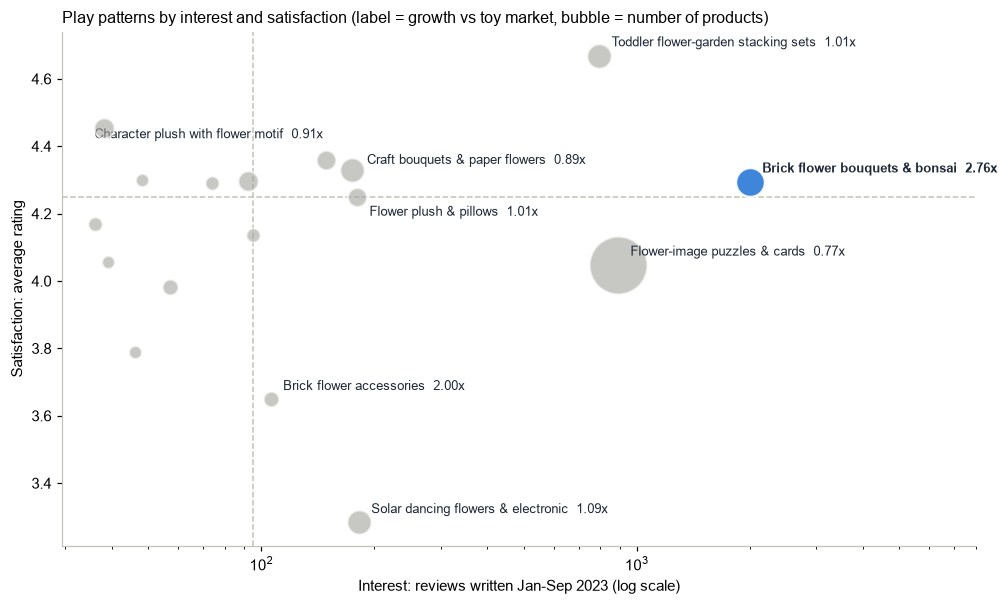

In [5]:
big = trend[trend.reviews >= 300]
fig, ax = plt.subplots(figsize=(9.5, 5.6))
nudge = {'Flower plush & pillows': (8, -12), 'Craft bouquets & paper flowers': (10, 4), 'Character plush with flower motif': (-2, 14)}
for _, r in big.iterrows():
    hero = r.play_pattern == BRICK
    ax.scatter(r.rv_2023, r.avg_rating, s=40 + r.products * 0.9, color=BLUE if hero else GREY,
               alpha=0.9 if hero else 0.6, edgecolor='white', linewidth=1.5, zorder=3)
    if r.rv_2023 >= 100:                      # label the patterns with real volume; small ones stay as dots
        dx, dy = nudge.get(r.pattern, (8, 6))
        ax.annotate(f"{r.pattern.split(' (')[0]}  {r.growth_vs_market:.2f}x", (r.rv_2023, r.avg_rating), xytext=(dx, dy),
                    textcoords='offset points', fontsize=8.5, color=INK, weight='bold' if hero else 'normal',
                    ha='right' if dx < 0 else 'left')
ax.axvline(big.rv_2023.median(), color='#c3c2b7', ls='--', lw=1)
ax.axhline(big.avg_rating.median(), color='#c3c2b7', ls='--', lw=1)
ax.set_xscale('log'); ax.set_xlim(right=big.rv_2023.max() * 4)
ax.set_xlabel('Interest: reviews written Jan-Sep 2023 (log scale)')
ax.set_ylabel('Satisfaction: average rating')
ax.set_title('Play patterns by interest and satisfaction (label = growth vs toy market, bubble = number of products)', loc='left', fontsize=10.5)
plt.tight_layout(); plt.show()

**Reading.** Adult brick flowers have the highest current interest of all flower toys and are the only large pattern growing far faster than the market (2.76x). Their rating sits at the median: buyers want the product but are not fully satisfied, so there is room for a better-made version.

## 3. Monthly trend
Monthly review volume per play pattern (`mart_flower_monthly_reviews`). Review volume stands in for sales.

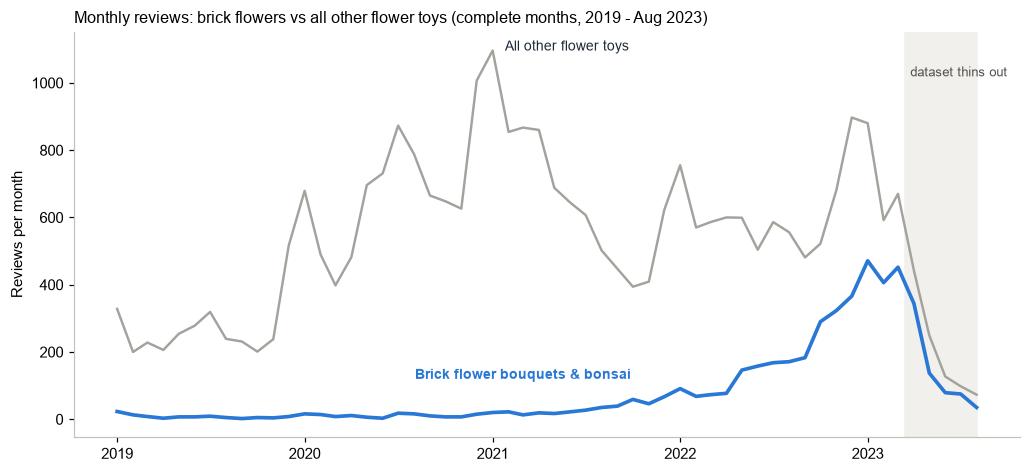

In [6]:
monthly = q('''
select review_month, play_pattern, reviews
from project2_marts.mart_flower_monthly_reviews
where review_month between date '2019-01-01' and date '2023-08-31'
''')
monthly['review_month'] = pd.to_datetime(monthly.review_month)
brick = monthly[monthly.play_pattern == BRICK].set_index('review_month').reviews.sort_index()
others = monthly[monthly.play_pattern != BRICK].groupby('review_month').reviews.sum().sort_index()
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(others.index, others.values, color=GREY, lw=1.6)
ax.plot(brick.index, brick.values, color=BLUE, lw=2.4)
ax.axvspan(pd.Timestamp('2023-03-15'), others.index.max(), color='#f1f0ec', zorder=0)
ax.text(pd.Timestamp('2023-03-25'), others.max() * 0.93, 'dataset thins out', fontsize=8.5, color='#52514e')
ax.text(pd.Timestamp('2021-03-01'), 120, 'Brick flower bouquets & bonsai', ha='center', fontsize=9, weight='bold', color=BLUE)
ax.annotate('All other flower toys', (others.idxmax(), others.max()), xytext=(8, 0), textcoords='offset points', fontsize=9, color=INK)
ax.set_ylabel('Reviews per month')
ax.set_title('Monthly reviews: brick flowers vs all other flower toys (complete months, 2019 - Aug 2023)', loc='left', fontsize=10.5)
plt.tight_layout(); plt.show()

In [7]:
yearly = q(f'''
select review_year, sum(reviews) as brick_flower_reviews
from project2_marts.mart_flower_monthly_reviews
where play_pattern = '{BRICK}' and month_of_year <= 9 and review_year between 2019 and 2023
group by 1 order by 1
''')
base = q('select review_year, jan_sep_reviews as all_toy_reviews from project2_marts.mart_review_baseline where review_year between 2019 and 2023 order by 1')
yearly = yearly.merge(base, on='review_year')
yearly['brick_flower_yoy_pct'] = yearly.brick_flower_reviews.pct_change() * 100
yearly['toy_market_yoy_pct'] = yearly.all_toy_reviews.pct_change() * 100
yearly

,review_year,brick_flower_reviews,all_toy_reviews,brick_flower_yoy_pct,toy_market_yoy_pct
0,2019,77,1387134,NaN,NaN
1,2020,102,1787182,32.47,28.84
2,2021,214,1764519,109.80,-1.27
3,2022,1135,1416593,430.37,-19.72
4,2023,2002,904907,76.39,-36.12


**Reading.** Brick-flower reviews rose every year, including 2023 when the whole toy dataset fell by about a third. Other flower toys peaked in 2020-21 and then declined, while brick flowers grew from a few percent of that volume in 2020 to about half of it by early 2023. Both lines peak around December-January: flower toys are bought as gifts.

The sharp drop after March 2023 is the dataset, not the market: reviews written shortly before the collection date are only partly captured, for every category. That is why growth is always compared with the whole toy market over the same months.

## 4. Top-selling products (by review volume)
`mart_flower_product_stats` keeps every product. There is no minimum review count; each product carries an evidence level instead.

In [8]:
top_products = q(f'''
select left(title, 62) as title, brand, review_count, reviews_2023_jan_sep as rv_2023, review_avg as avg_rating,
       low_rating_pct, price, evidence_level
from project2_marts.mart_flower_product_stats
where play_pattern = '{BRICK}'
order by reviews_2023_jan_sep desc, review_count desc
limit 12
''')
top_products

,title,brand,review_count,rv_2023,avg_rating,low_rating_pct,price,evidence_level
0,LEGO Icons Orchid 10311 Artificial Plant Building Set with Flo,lego,522,257,4.82,2.49,40.00,strong (30+ reviews)
1,LEGO Icons Bonsai Tree Building Set 10281 - Featuring Cherry B,lego,621,142,4.65,5.48,39.99,strong (30+ reviews)
2,"ZIYOSTAR Mini Bricks Cherry Blossoms Plant Building Kit,Sakura",ziyostar,128,128,4.52,2.34,11.99,strong (30+ reviews)
3,QLT Mini Bricks Bonsai Model Creative DIY Simulation Mini Part,qlt qiaoletong,135,46,3.87,21.48,17.99,strong (30+ reviews)
4,Bestbase Flower Bouquets Building Toys - 596 PCS Red Rose Buil,bestbase,39,39,3.95,15.38,17.99,strong (30+ reviews)
5,Baoswi Flower Bouquet Building Sets Artificial Flowers Botanic,baoswi,38,38,4.66,2.63,11.99,strong (30+ reviews)
6,"Rose Flower Building Kits, Artificial Flowers Bouquet Building",libergarden,44,36,4.39,2.27,9.99,strong (30+ reviews)
7,Sopu 1277 Pcs Flower Bouquet Building Kit Bonsai Rose Fower Ba,sopu,36,36,3.67,25.00,25.99,strong (30+ reviews)
8,"EDUCIRO Flowers Toys Building Blocks for Adults, 3 Pack Botani",educiro,34,34,4.24,5.88,17.75,strong (30+ reviews)
9,"Cieyan Flower Bouquets Building Sets, 630PCS Building Blocks,",cieyan,29,29,4.00,10.34,17.99,medium (5-29 reviews)


In [9]:
q(f'''
select case when is_lego_brand then 'LEGO' else 'Other brands' end as brand_group,
       count(*) as products, sum(review_count) as reviews,
       sum(reviews_2022_jan_sep) as rv_2022, sum(reviews_2023_jan_sep) as rv_2023,
       sum(review_avg * review_count) / sum(review_count) as avg_rating,
       sum(low_rating_pct * review_count) / sum(review_count) as low_rating_pct
from project2_marts.mart_flower_product_stats
where play_pattern = '{BRICK}'
group by 1 order by 1
''')

,brand_group,products,reviews,rv_2022,rv_2023,avg_rating,low_rating_pct
0,LEGO,11,1228,427,405,4.72,4.32
1,Other brands,339,3565,708,1597,4.15,13.13


**Reading.** LEGO sets lead the ranking and hold the best ratings, but most of the 2023 volume and almost all of the growth comes from other brands, which are rated lower and collect more low ratings. Demand is there; quality outside LEGO is the gap.

## 5. Customer segmentation by purchase behaviour
`mart_flower_customer_segments`: one row per customer who reviewed a flower toy, joined to `dim_customer` (lifetime behaviour across all toys).

In [10]:
loyalty = q('''
select flower_loyalty_segment as segment, count(*) as customers, avg(flower_avg_rating) as avg_flower_rating,
       avg(lifetime_review_count) as avg_lifetime_reviews, avg(flower_share_of_reviews) * 100 as flower_share_of_their_reviews_pct
from project2_marts.mart_flower_customer_segments group by 1 order by 1
''')
loyalty['share_of_customers_pct'] = loyalty.customers / loyalty.customers.sum() * 100
loyalty

,segment,customers,avg_flower_rating,avg_lifetime_reviews,flower_share_of_their_reviews_pct,share_of_customers_pct
0,1 single flower purchase,39749,4.18,5.82,54.19,96.54
1,2 repeat flower buyer (2 products),1112,4.37,25.10,34.03,2.70
2,3 flower collector (3+ products),313,4.51,85.30,21.62,0.76


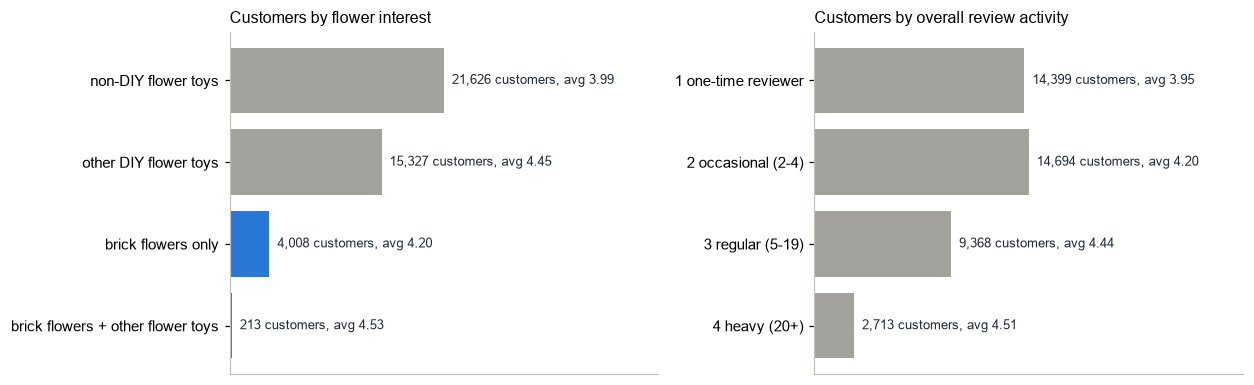

,segment,customers,avg_flower_rating,avg_lifetime_reviews
0,non-DIY flower toys,21626,3.99,5.85
1,other DIY flower toys,15327,4.45,7.24
2,brick flowers only,4008,4.20,8.21
3,brick flowers + other flower toys,213,4.53,72.82


In [11]:
interest = q('''
select flower_interest_segment as segment, count(*) as customers, avg(flower_avg_rating) as avg_flower_rating,
       avg(lifetime_review_count) as avg_lifetime_reviews
from project2_marts.mart_flower_customer_segments group by 1 order by 2 desc
''')
activity = q('''
select activity_segment as segment, count(*) as customers, avg(flower_avg_rating) as avg_flower_rating
from project2_marts.mart_flower_customer_segments group by 1 order by 1
''')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
for ax, frame, title in [(axes[0], interest, 'Customers by flower interest'), (axes[1], activity, 'Customers by overall review activity')]:
    colors = [BLUE if 'brick' in s else GREY for s in frame.segment]
    bars = ax.barh(frame.segment, frame.customers, color=colors if ax is axes[0] else GREY)
    for b, r in zip(bars, frame.avg_flower_rating):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f'  {b.get_width():,.0f} customers, avg {r:.2f}', va='center', fontsize=8.5, color=INK)
    ax.set_title(title, loc='left', fontsize=10.5); ax.invert_yaxis(); ax.set_xlim(0, frame.customers.max() * 2.0); ax.set_xticks([])
plt.tight_layout(); plt.show()
interest

**Reading.** Most flower-toy customers buy once (gift purchases). A small group returns for a second and third product; they rate higher and are heavy reviewers overall. They are the natural audience for series and add-on packs. Customers who bought brick flowers *and* another flower toy are the most satisfied segment.

## 6. Why people buy brick flowers, and what to improve
`mart_flower_theme_evidence` (regex codebook on review text) and `mart_flower_need_evidence` (sentences where buyers say what they wish the product had). Evidence tier: strong = 30+ reviews **and** 10+ products **and** 5+ brands.

In [12]:
themes = q(f'''
select theme_group as grp, theme, mentions, mention_pct, avg_rating_when_mentioned as rating_when_mentioned,
       share_of_low_reviews_pct, products, brands, evidence
from project2_marts.mart_flower_theme_evidence
where play_pattern = '{BRICK}' and mentions >= 20
''')
themes[themes.grp.str.startswith('Motive')].sort_values('mention_pct', ascending=False).head(10).drop(columns=['share_of_low_reviews_pct'])

,grp,theme,mentions,mention_pct,rating_when_mentioned,products,brands,evidence
2,Motive: gifting,Bought as a gift,977,20.38,4.63,185,142,strong
27,Motive: value,Home or desk decor,640,13.35,4.69,135,109,strong
20,Motive: gifting,Gift for a girl,438,9.14,4.54,127,106,strong
28,Motive: gifting,Gift for a partner,281,5.86,4.61,91,74,strong
4,Motive: gifting,Gift for a boy,275,5.74,4.53,104,85,strong
29,Motive: gifting,Christmas & holidays,160,3.34,4.62,65,54,strong
22,Motive: value,Learning & fine-motor skills,156,3.25,4.32,78,71,strong
25,Motive: value,Collecting a series,146,3.05,4.52,71,57,strong
12,Motive: gifting,Birthday,116,2.42,4.70,44,39,strong
10,Motive: value,"Relaxing, mindful build",107,2.23,4.59,57,52,strong


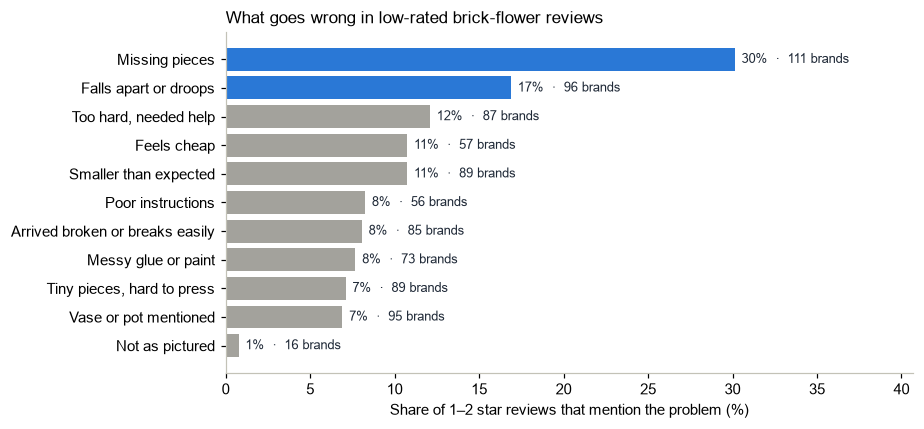

In [13]:
pains = themes[themes.grp.str.startswith('Experience') & (themes.rating_when_mentioned < 4.2)].sort_values('share_of_low_reviews_pct', ascending=True)
fig, ax = plt.subplots(figsize=(8.5, 4))
bars = ax.barh(pains.theme, pains.share_of_low_reviews_pct, color=[BLUE if v >= 15 else GREY for v in pains.share_of_low_reviews_pct])
for b, n in zip(bars, pains.brands):
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f'{b.get_width():.0f}%  ·  {n} brands', va='center', fontsize=8.5, color=INK)
ax.set_xlabel('Share of 1–2 star reviews that mention the problem (%)'); ax.set_xlim(0, pains.share_of_low_reviews_pct.max() * 1.35)
ax.set_title('What goes wrong in low-rated brick-flower reviews', loc='left', fontsize=11)
plt.tight_layout(); plt.show()

In [14]:
q(f'''
select need as unmet_need, sentences as wish_sentences, products, brands, avg_rating, evidence
from project2_marts.mart_flower_need_evidence
where play_pattern = '{BRICK}' and need != 'Uncategorised'
order by sentences desc limit 10
''')

,unmet_need,wish_sentences,products,brands,avg_rating,evidence
0,Clearer instructions or video,124,60,51,3.06,strong
1,Include a vase or pot,34,20,18,4.41,strong
2,Sturdier stems and joints,31,21,21,4.00,strong
3,Stable base,28,20,19,4.39,medium
4,Better durability,27,21,21,3.26,medium
5,Numbered bags and spare parts,24,19,19,3.96,medium
6,Difficulty matched to age,19,15,15,4.37,medium
7,No-glue assembly,19,15,14,3.53,medium
8,Lights,17,11,10,3.94,medium
9,"More flowers, fuller look",13,11,11,3.69,medium


**Reading.** People buy brick flowers as a gift and as decor: a flower that lasts. What fails is the making: missing pieces and builds that fall apart dominate low ratings, across roughly a hundred brands. Buyers ask for clearer instructions, a vase, sturdier stems and numbered bags. These are the product specifications for the store.

## 7. Is DIY itself the trend?

In [15]:
q('select * from project2_marts.mart_flower_diy_2023 order by relative_growth_index desc')

,diy_family,products,brands,reviews_2022_jan_sep,reviews_2023_jan_sep,yoy_pct,relative_growth_index
0,DIY: adult brick building,425,257,1221,2164,77.23,2.77
1,"Not DIY (plush, decor, electronic, miniature, pretend)",982,614,1303,865,-33.61,1.04
2,DIY: toddler stacking,237,186,1235,795,-35.63,1.01
3,DIY: crafts,386,255,661,363,-45.08,0.86
4,Puzzles & cards (flower is only the image),1546,754,1803,892,-50.53,0.77
5,DIY: planting,74,60,149,57,-61.74,0.60


**Reading.** In 2023 only one DIY family, adult brick building, beat the market. Toddler stacking sets moved with the market; crafts and planting kits fell behind. So the 2023 evidence supports "build a bouquet", not DIY in general.

## 8. Amazon 2026: does the 2023 answer still hold?
The review dataset stops in 2023, so I checked today's market with a Keepa API snapshot (2026-10-07): the current top 50 products of seven groups, products first listed since 2024, and the 2023 top products followed into 2026.

Three signals per group (`mart_keepa_group_verdict`):
- **S1** rating count added 1 Jan - 7 Oct 2026 vs the same window in 2025
- **S2** units sold per month now vs a year ago
- **S3** products listed since 2024 that sell 50+ a month, compared with the median group

Two or three signals up = trending, one = stable, none = not trending.

In [16]:
verdict = q('''
select keepa_group as product_group, products_analyzed as products, reviews_added_2025, reviews_added_2026,
       s1_reviews_2026_vs_2025_pct as s1_reviews_pct, s2_monthly_sold_yoy_pct as s2_sold_pct,
       s3_new_since_2024_selling_50_plus as s3_new_sellers, products_selling_100_plus,
       rating_now_median as rating, price_now_median as price, signals_up, verdict
from project2_marts.mart_keepa_group_verdict order by keepa_group
''')
verdict

,product_group,products,reviews_added_2025,reviews_added_2026,s1_reviews_pct,s2_sold_pct,s3_new_sellers,products_selling_100_plus,rating,price,signals_up,verdict
0,G1 Adult brick flowers (non-LEGO),50,"2,124.00","6,255.00",194.49,70.64,65,56,4.50,28.98,3,trending
1,G2 LEGO flower sets,15,"6,136.00","4,746.00",-22.65,111.16,28,42,4.90,18.68,2,trending
2,G3 Toddler flower-garden sets,17,"1,619.00","1,577.00",-2.59,-22.14,3,31,4.65,20.49,0,not trending
3,G4 Flower crafts,50,"3,638.00","5,229.00",43.73,-45.32,25,42,4.60,19.99,2,trending
4,G5 Planting kits,24,"1,332.00",934.00,-29.88,-9.68,0,5,4.50,24.99,0,not trending
5,G6 Flower plush,26,547.00,804.00,46.98,-40.91,4,29,4.65,17.99,1,stable
6,G7 Solar dancing flowers,40,230.00,243.00,5.65,-70.00,2,3,4.00,6.39,1,stable


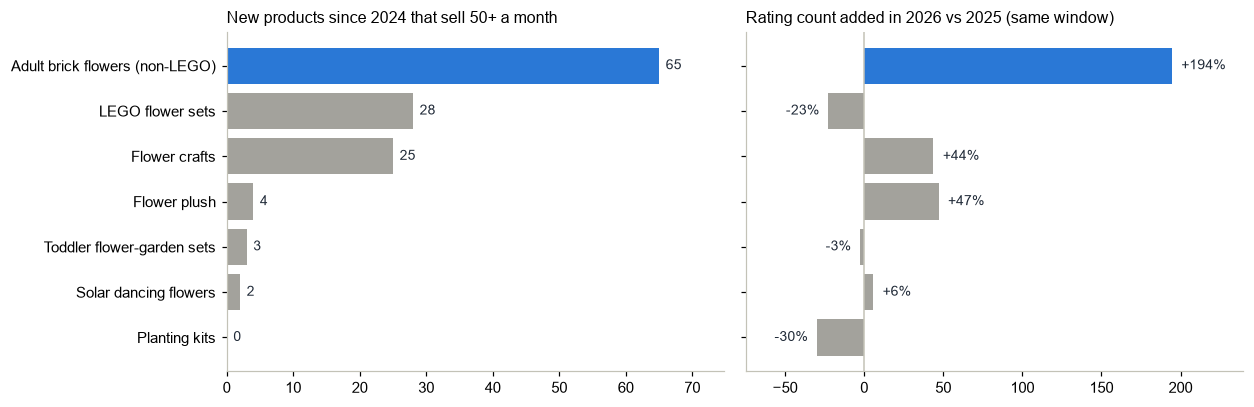

In [17]:
v = verdict.sort_values('s3_new_sellers')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
hero = [BLUE if g.startswith('G1') else GREY for g in v.product_group]
names = [g[3:] for g in v.product_group]
axes[0].barh(names, v.s3_new_sellers, color=hero)
for y, n in enumerate(v.s3_new_sellers):
    axes[0].text(n + 1, y, f'{n:.0f}', va='center', fontsize=9, color=INK)
axes[0].set_title('New products since 2024 that sell 50+ a month', loc='left', fontsize=10.5)
axes[1].barh(names, v.s1_reviews_pct, color=hero)
for y, n in enumerate(v.s1_reviews_pct):
    axes[1].text(n + (6 if n >= 0 else -6), y, f'{n:+.0f}%', va='center', ha='left' if n >= 0 else 'right', fontsize=9, color=INK)
axes[1].axvline(0, color='#c3c2b7', lw=1)
axes[1].set_title('Rating count added in 2026 vs 2025 (same window)', loc='left', fontsize=10.5)
axes[1].set_xlim(v.s1_reviews_pct.min() - 45, v.s1_reviews_pct.max() + 45)
axes[0].set_xlim(0, v.s3_new_sellers.max() * 1.15)
plt.tight_layout(); plt.show()

**Reading.** Non-LEGO brick flowers are trending on all three signals: reviews nearly tripled against 2025 and 65 new products since 2024 already sell 50+ a month, more than any other group. LEGO's own flower sets sell far more units but their review growth is negative, because LEGO keeps replacing older sets with new ones. Planting kits and toddler garden sets are not trending, as in 2023. Flower crafts changed: behind the market in 2023, trending in 2026.

Non-LEGO brick flowers still rate lower than LEGO (4.5 vs 4.9), so the quality gap found in the 2023 reviews is still open.

In [18]:
q('''
select new_form as product_form, products, selling_50_plus, monthly_sold_sum as units_per_month, brands,
       rating_median as rating, price_median as price
from project2_marts.mart_keepa_new_forms
where new_form not in ('Other', 'Other crafts')
order by monthly_sold_sum desc
''')

,product_form,products,selling_50_plus,units_per_month,brands,rating,price
0,New LEGO flower sets,33,32,"71,800.00",1,4.90,23.99
1,Other brick bouquets & bonsai,91,71,"14,000.00",74,4.50,29.19
2,Other flower & succulent plush,27,16,"6,450.00",22,4.75,18.51
3,Gothic & dark-romance brick flowers,18,14,"5,450.00",16,4.60,28.98
4,Single-stem & mini flower brick series,25,24,"5,150.00",19,4.20,19.95
5,Fabric bouquet & flower-shop kits for kids,22,10,"4,400.00",21,4.70,16.97
6,Flower press kits,10,9,"3,500.00",10,4.45,22.99
7,Bouquet-format collectibles (blind box / licensed),10,9,"2,800.00",6,4.70,16.49
8,"Poke-art, no-glue bouquet kits",7,4,"2,100.00",7,4.60,17.99
9,Flower advent calendars,5,4,900.00,3,4.80,30.76


In [19]:
cohort = q('''
select keepa_group as product_group, count(*) as products_2023_top, countif(sales_rank_now is not null) as still_ranked,
       sum(reviews_added_2023) as added_2023, sum(reviews_added_2025) as added_2025, sum(reviews_added_2026) as added_2026
from project2_analytics.fact_keepa_snapshot
where source = 'cohort'
group by 1 order by 1
''')
cohort

,product_group,products_2023_top,still_ranked,added_2023,added_2025,added_2026
0,G1 Adult brick flowers (non-LEGO),4,3,108.00,45.00,18.00
1,G2 LEGO flower sets,8,5,"16,428.00","5,095.00","2,337.00"
2,G3 Toddler flower-garden sets,13,13,"3,818.00","1,715.00",869.00
3,G4 Flower crafts,17,17,"3,071.00","1,135.00","2,845.00"
4,G5 Planting kits,11,5,66.00,887.00,5.00
5,G6 Flower plush,12,11,"1,054.00",233.00,538.00
6,G7 Solar dancing flowers,16,12,678.00,278.00,187.00


**Reading.** What is new since 2024: gothic and dark-romance brick flowers, single-stem and mini flower series, fabric bouquet kits for kids, and no-glue "poke art" bouquets. The last one answers the glue-and-mess complaint from the 2023 craft reviews.

The cohort table is a warning for running the store: in most groups the top products of 2023 collect far fewer reviews in 2026 (flower crafts are the exception, and only 4 of the 20 brick-flower products from 2023 could still be matched). Growth comes from new products replacing old ones, so the range has to be refreshed regularly.

## Conclusion
- **Sell adult brick flowers.** Highest interest among flower toys in 2023 (growth 2.76x the market) and still trending in 2026.
- **Compete on the making experience**: complete, numbered parts; clear instructions; sturdy stems; a vase included.
- **Design for gifting and for the returning collector**: series and add-on packs; themed lines (gothic, single stems) are where new products are entering.

## Limits
- Review counts and rating counts are demand proxies, not sales. Keepa's monthly-sold figure is Amazon's rounded "bought in past month" badge.
- One US marketplace. The review data ends in September 2023 and is incomplete after March 2023.
- Themes and needs come from a rule-based codebook that I checked on samples; it is not labelled data.
- The 2026 view looks at today's top products, which favours recent winners; the cohort view favours ageing products. I read them together.